# 🧪 04 · Train models & track them with MLflow
### Entrenar modelos y registrarlos con MLflow

| | |
|---|---|
| 🍳 **Analogy / Analogía** | *Trying several recipes and writing everything in a lab notebook* · *Probar recetas y anotarlo todo en un cuaderno* |
| 🎯 **Goal / Objetivo** | Compare models fairly and never lose a result · Comparar modelos de forma justa y no perder nunca un resultado |
| 🏭 **Becomes / Se convierte en** | `src/models/train.py` |

```
  ┌─────────────── MLflow run ────────────────┐
  │ params:    max_depth=3, learning_rate=0.03 │   ← the recipe  / la receta
  │ metrics:   roc_auc=0.514, accuracy=0.515   │   ← the score   / la nota
  │ artifacts: confusion.png, equity.png       │   ← the photos  / las fotos
  │ model:     model.pkl + signature           │   ← the dish    / el plato
  │ tags:      git_commit=abc123               │   ← the version / la versión
  └────────────────────────────────────────────┘
```

In [1]:
import os
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)

import warnings

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import KFold, TimeSeriesSplit, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (11, 4)

path = "data/processed/features.csv"
if not Path(path).exists():  # e.g. fresh clone without `dvc pull`
    import sys; sys.path.insert(0, str(ROOT))
    from src.features.build import make_features
    from src.utils import load_params
    make_features(pd.read_csv("data/sample/xauusd_h1_sample.csv"), load_params()["features"]).to_csv(
        path := "data/processed/features_sample.csv", index=False)
df = pd.read_csv(path, parse_dates=["time"])
features = [c for c in df.columns if c not in ("time", "close", "target")]
print(df.shape, "features:", len(features))

(29799, 21) features: 18


## 1️⃣ Never shuffle time! / ¡Nunca mezcles el tiempo!

```
 ❌ Random K-Fold (shuffled)           ✅ Walk-forward (TimeSeriesSplit)
 fold1: ▓░▓▓░▓░▓▓░  (train/test mixed)  fold1: ▓▓░
 fold2: ░▓▓░▓▓▓░▓▓                       fold2: ▓▓▓▓░
 → trains on the FUTURE to predict       fold3: ▓▓▓▓▓▓░
   the PAST = cheating                   → always train on the past, test on what comes next
```

In [2]:
X, y = df[features], df["target"]
model = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, n_jobs=-1, eval_metric="logloss")

auc_shuffled = cross_val_score(model, X, y, cv=KFold(5, shuffle=True, random_state=0), scoring="roc_auc").mean()
auc_walkfwd = cross_val_score(model, X, y, cv=TimeSeriesSplit(5), scoring="roc_auc").mean()
print(f"Shuffled K-Fold AUC : {auc_shuffled:.4f}   ← over-optimistic / demasiado optimista")
print(f"Walk-forward AUC    : {auc_walkfwd:.4f}   ← realistic / realista")

Shuffled K-Fold AUC : 0.5164   ← over-optimistic / demasiado optimista
Walk-forward AUC    : 0.5139   ← realistic / realista


**EN:** Here the gap is small because our target only looks 1 hour ahead. With longer horizons (e.g. "will it be
higher in 24h?") neighbouring rows share the same future, and shuffling leaks it → the shuffled score becomes
**much** better than reality. Walk-forward is the only honest way — so we always use it.

**ES:** Aquí la diferencia es pequeña porque el objetivo solo mira 1 hora adelante. Con horizontes largos (ej. "¿estará
más arriba en 24h?") las filas vecinas comparten el mismo futuro y mezclar lo filtra → la nota mezclada sale
**mucho** mejor que la realidad. Walk-forward es la única forma honesta — por eso siempre la usamos.

## 2️⃣ Train/test split in time / División en el tiempo

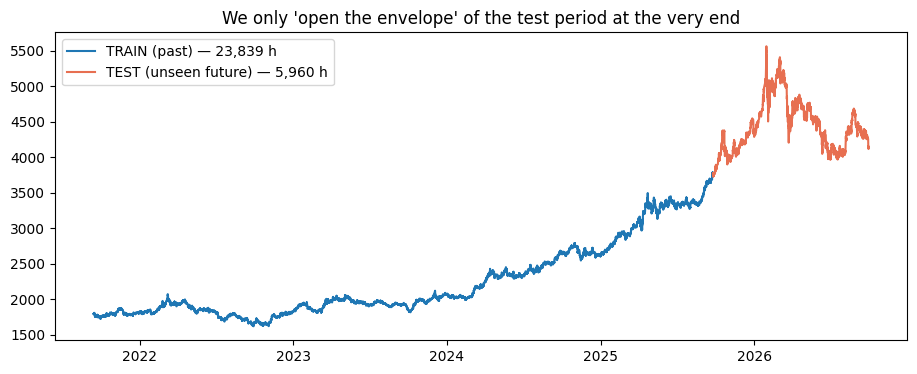

In [3]:
cut = int(len(df) * 0.8)
train, test = df.iloc[:cut], df.iloc[cut:]
fig, ax = plt.subplots()
ax.plot(train.time, train.close, color="#1f77b4", label=f"TRAIN (past) — {len(train):,} h")
ax.plot(test.time, test.close, color="#e76f51", label=f"TEST (unseen future) — {len(test):,} h")
ax.legend()
ax.set_title("We only 'open the envelope' of the test period at the very end")
plt.show()

## 3️⃣ Track experiments with MLflow / Registrar experimentos con MLflow
**EN:** We log these notebook trials in a separate *sandbox* experiment so they don't mix with the official pipeline.
**ES:** Registramos las pruebas del notebook en un experimento *sandbox* aparte para no mezclarlas con el pipeline oficial.

In [4]:
mlflow.set_tracking_uri(f"sqlite:///{(ROOT / 'mlflow.db').as_posix()}")
if mlflow.get_experiment_by_name("notebook-sandbox") is None:
    mlflow.create_experiment("notebook-sandbox", artifact_location=(ROOT / "mlartifacts").as_uri())
mlflow.set_experiment("notebook-sandbox")

candidates = {
    "baseline": DummyClassifier(strategy="most_frequent"),
    "logreg": make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=1000)),
    "xgb_shallow": XGBClassifier(n_estimators=300, max_depth=2, learning_rate=0.03, n_jobs=-1),
    "xgb_deep": XGBClassifier(n_estimators=300, max_depth=8, learning_rate=0.1, n_jobs=-1),
}
rows = []
for name, m in candidates.items():
    with mlflow.start_run(run_name=name):
        m.fit(train[features], train["target"])
        proba = m.predict_proba(test[features])[:, 1]
        res = {"train_auc": roc_auc_score(train["target"], m.predict_proba(train[features])[:, 1]),
               "test_auc": roc_auc_score(test["target"], proba),
               "test_accuracy": accuracy_score(test["target"], (proba > 0.5).astype(int))}
        mlflow.log_params({"model": name})
        mlflow.log_metrics(res)
        rows.append({"model": name, **res})

results = pd.DataFrame(rows).set_index("model").round(4)
results

2026/09/28 22:29:01 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/09/28 22:29:01 INFO mlflow.store.db.utils: Updating database tables


INFO  [alembic.runtime.migration] Context impl SQLiteImpl.


INFO  [alembic.runtime.migration] Will assume non-transactional DDL.


INFO  [alembic.runtime.migration] Context impl SQLiteImpl.


INFO  [alembic.runtime.migration] Will assume non-transactional DDL.


,train_auc,test_auc,test_accuracy
model,,,
baseline,0.5000,0.5000,0.5092
logreg,0.5249,0.5028,0.5045
xgb_shallow,0.5753,0.5115,0.5081
xgb_deep,0.9993,0.5008,0.4975


## 4️⃣ Overfitting: memorizing vs learning / Memorizar vs aprender

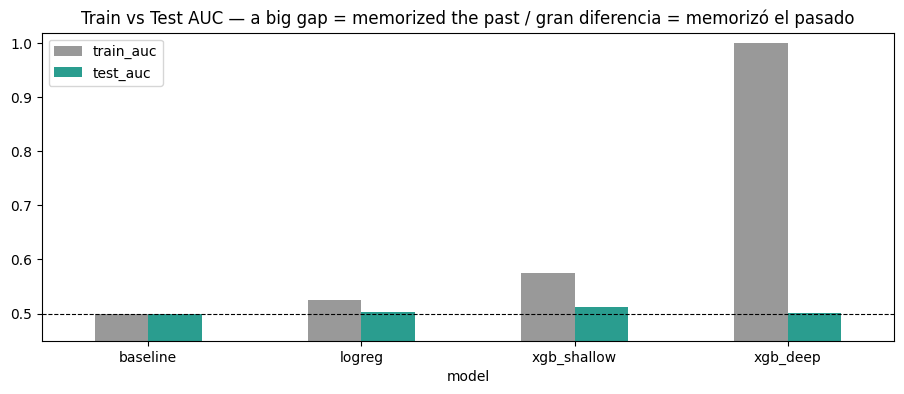

In [5]:
ax = results[["train_auc", "test_auc"]].plot.bar(color=["#999999", "#2a9d8f"], rot=0)
ax.axhline(0.5, color="black", ls="--", lw=0.8)
ax.set_ylim(0.45, max(0.8, results.train_auc.max() + 0.02))
ax.set_title("Train vs Test AUC — a big gap = memorized the past / gran diferencia = memorizó el pasado")
plt.show()

**EN:** `xgb_deep` scores great on the past (train) but not on the future (test) → **overfitting**:
it memorized noise. Simpler models generalize better on noisy markets.

**ES:** `xgb_deep` saca gran nota en el pasado (train) pero no en el futuro (test) → **sobreajuste**:
memorizó ruido. En mercados ruidosos, los modelos simples generalizan mejor.

## 5️⃣ Look at it in the MLflow UI / Míralo en la interfaz de MLflow
```powershell
mlflow ui --backend-store-uri sqlite:///mlflow.db
# → open http://localhost:5000
```
👉 Select several runs → **Compare** → charts of params vs metrics.

## 6️⃣ Query MLflow from code / Consultar MLflow desde código

In [6]:
runs = mlflow.search_runs(experiment_names=["notebook-sandbox"], order_by=["metrics.test_auc DESC"])
runs[["tags.mlflow.runName", "metrics.test_auc", "metrics.train_auc", "start_time"]].head(8)

,tags.mlflow.runName,metrics.test_auc,metrics.train_auc,start_time
0,xgb_shallow,0.511503,0.575350,2026-09-29 04:29:04.365000+00:00
1,xgb_shallow,0.511503,0.575350,2026-09-29 04:23:37.578000+00:00
2,logreg,0.502768,0.524944,2026-09-29 04:29:03.943000+00:00
3,logreg,0.502768,0.524944,2026-09-29 04:23:37.149000+00:00
4,xgb_deep,0.500772,0.999350,2026-09-29 04:29:06.005000+00:00
5,xgb_deep,0.500772,0.999350,2026-09-29 04:23:39.423000+00:00
6,baseline,0.500000,0.500000,2026-09-29 04:29:03.439000+00:00
7,baseline,0.500000,0.500000,2026-09-29 04:23:36.891000+00:00


---
## 🔁 From notebook to production / Del notebook a producción

| Notebook | Production (`src/models/train.py`) |
|---|---|
| Hyper-params typed in the cell | `params.yaml → train.models.*` |
| `notebook-sandbox` experiment | `gold-direction-h1` experiment, parent run + one **nested run per model** |
| Only metrics logged | params + metrics + **plots** + **model with signature** + **git commit tag** |
| Scaler separate from model | Everything in an sklearn `Pipeline` → travels together to the API |
| Manual ▶ | `dvc repro train` — only re-runs when data/params/code change |